In [1]:
# Install any missing libraries in a notebook cell
%pip install pandas numpy matplotlib seaborn scikit-learn joblib

In [2]:
#Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
# Load the processed data
X = pd.read_csv("clients_features_processed.csv")
client_ids = pd.read_csv("client_ids_for_clustering.csv")

assert len(X) == len(client_ids), "Feature and ID row counts differ!"
assert client_ids["client_id"].is_unique, "Client IDs are not unique!"

assert X.notna().all().all(), "Missing values found in features!"
assert np.isfinite(X.to_numpy()).all(), "Infinite values found!"

print("Number of customers:", len(X))
print("Number of processed features:", X.shape[1])

display(X.head())

Number of customers: 2000
Number of processed features: 80


,categorical__client_type_Company,categorical__client_type_Individual,categorical__gender_F,categorical__gender_M,categorical__country_Australia,categorical__country_Belgium,categorical__country_Canada,categorical__country_Denmark,categorical__country_France,categorical__country_Germany,...,categorical__region_Zealand,categorical__acquisition_purpose_Home,categorical__acquisition_purpose_Investment,categorical__loan_applied_No,categorical__loan_applied_Yes,categorical__referral_channel_Agency,categorical__referral_channel_Client,categorical__referral_channel_Website,numeric__age,numeric__satisfaction_score
0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.109549,0.687089
1,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.455585,-1.435740
2,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.628603,0.687089
3,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.628603,1.394698
4,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,-0.351832,1.394698


In [4]:
# Find the optimal number of clusters
k_values = range(2, 11)

inertias = []
silhouette_scores = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X)

    inertias.append(model.inertia_)
    silhouette_scores.append(
        silhouette_score(X, labels)
    )

results = pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertias,
    "Silhouette Score": silhouette_scores
})

display(results)

,K,Inertia,Silhouette Score
0,2,9160.288993,0.134463
1,3,8213.797532,0.120625
2,4,7674.813487,0.104625
3,5,7343.252431,0.102398
4,6,7058.939703,0.099620
5,7,6844.509705,0.096883
6,8,6673.674338,0.094803
7,9,6503.549245,0.095693
8,10,6355.945467,0.096960


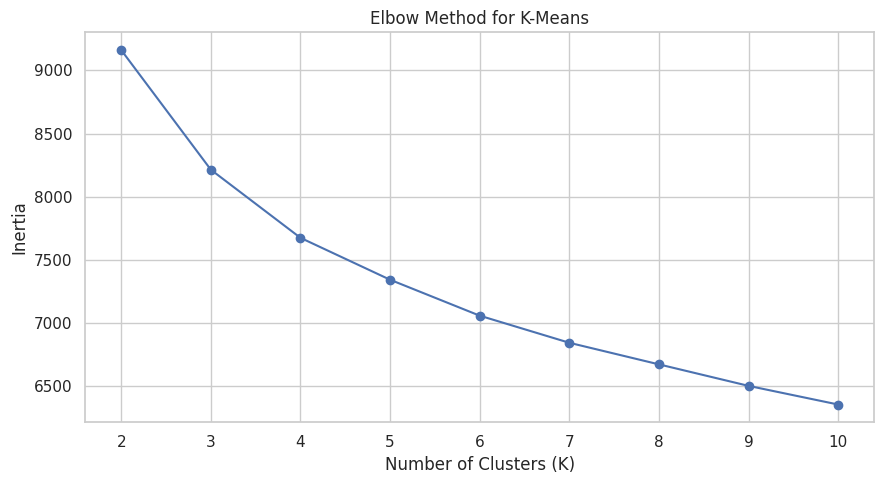

In [5]:
# Plot the Elbow Method
plt.figure(figsize=(9, 5))

plt.plot(
    results["K"],
    results["Inertia"],
    marker="o"
)

plt.title("Elbow Method for K-Means")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.xticks(list(k_values))
plt.tight_layout()
plt.show()

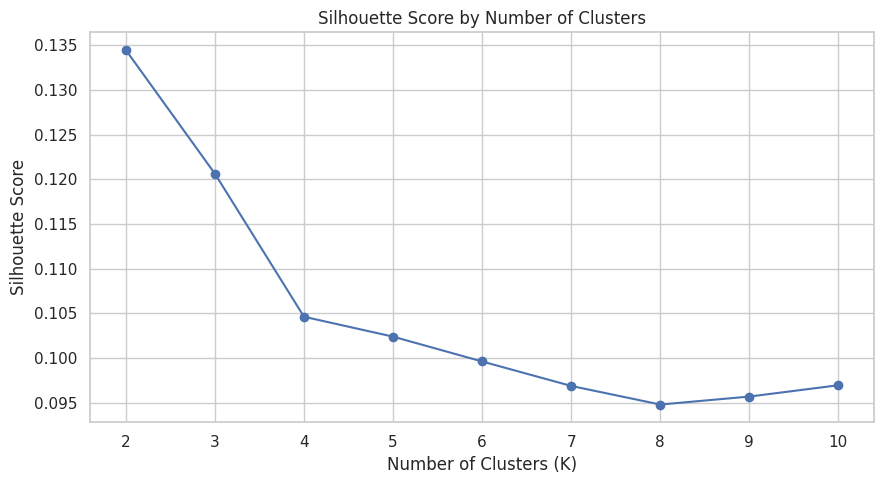

Highest silhouette score occurs at K = 2


In [6]:
# Plot Silhouette Scores
plt.figure(figsize=(9, 5))

plt.plot(
    results["K"],
    results["Silhouette Score"],
    marker="o"
)

plt.title("Silhouette Score by Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(list(k_values))
plt.tight_layout()
plt.show()

best_k_silhouette = int(
    results.loc[
        results["Silhouette Score"].idxmax(), "K"
    ]
)

print("Highest silhouette score occurs at K =", best_k_silhouette)

In [7]:
# Train the final K-Means model
FINAL_K = best_k_silhouette

kmeans_model = KMeans(
    n_clusters=FINAL_K,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans_model.fit_predict(X)

print("Selected K:", FINAL_K)
print("K-Means clustering completed.")

Selected K: 2
K-Means clustering completed.


,Customer Count
Cluster,
0,774
1,1226


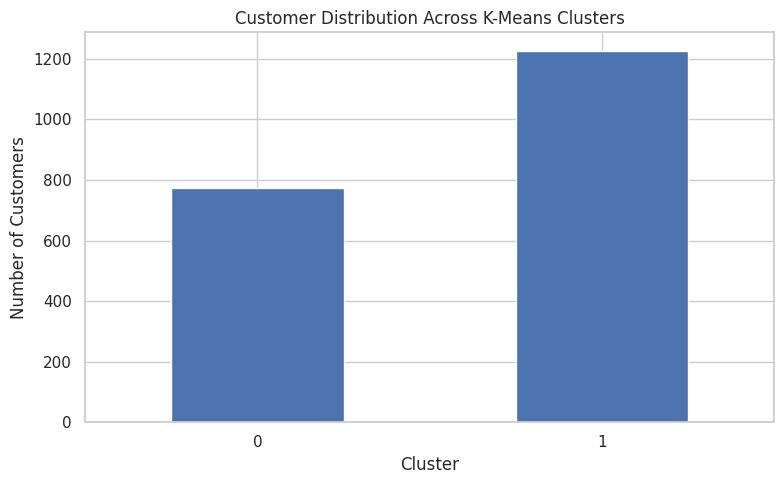

In [8]:
# Examine cluster distribution
cluster_counts = pd.Series(
    kmeans_labels,
    name="Cluster"
).value_counts().sort_index()

display(
    cluster_counts.to_frame("Customer Count")
)

cluster_counts.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Customer Distribution Across K-Means Clusters")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [9]:
# Train Hierarchical Clustering
hierarchical_model = AgglomerativeClustering(
    n_clusters=FINAL_K,
    linkage="ward"
)

hierarchical_labels = hierarchical_model.fit_predict(X)

print("Hierarchical clustering completed.")

hierarchical_counts = pd.Series(
    hierarchical_labels,
    name="Cluster"
).value_counts().sort_index()

display(
    hierarchical_counts.to_frame("Customer Count")
)

Hierarchical clustering completed.


,Customer Count
Cluster,
0,935
1,1065


In [10]:
# Compare the algorithms
comparison = pd.DataFrame({
    "Algorithm": [
        "K-Means",
        "Hierarchical Clustering"
    ],
    "Number of Clusters": [
        len(np.unique(kmeans_labels)),
        len(np.unique(hierarchical_labels))
    ],
    "Silhouette Score": [
        silhouette_score(X, kmeans_labels),
        silhouette_score(X, hierarchical_labels)
    ]
})

display(comparison)

,Algorithm,Number of Clusters,Silhouette Score
0,K-Means,2,0.134463
1,Hierarchical Clustering,2,0.108522


Variance explained by two components: 0.3762


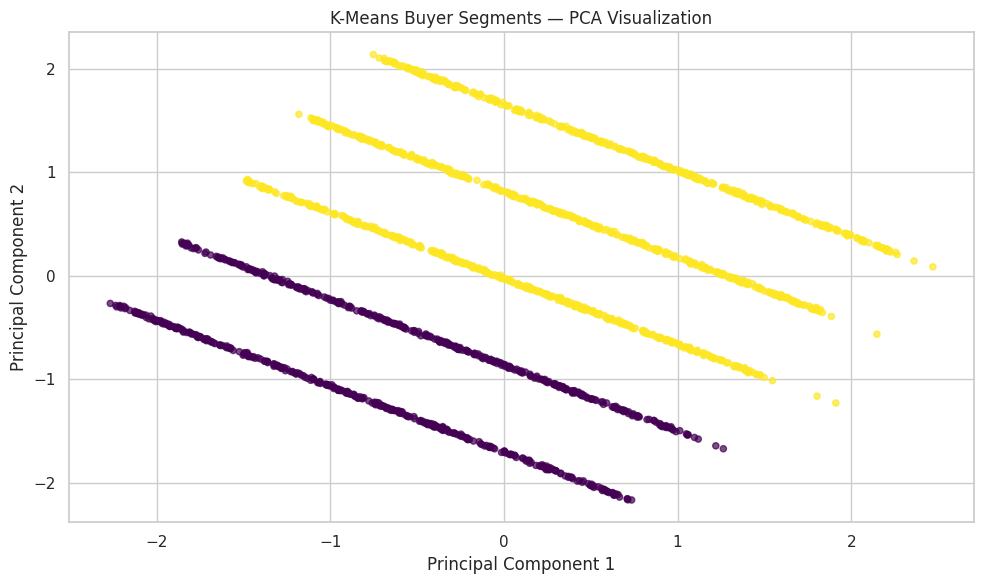

In [11]:
# Visualize clusters using PCA
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X)

print(
    "Variance explained by two components:",
    round(pca.explained_variance_ratio_.sum(), 4)
)

plt.figure(figsize=(10, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=kmeans_labels,
    cmap="viridis",
    alpha=0.7,
    s=20
)

plt.title("K-Means Buyer Segments — PCA Visualization")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.tight_layout()
plt.show()

In [13]:
# Interpret buyer segments
# Reload the original cleaned customer data
clients = pd.read_csv("clients_cleaned.csv")

clustered_clients = clients.copy()
clustered_clients["cluster"] = kmeans_labels

print("Cluster profiles: customer counts")
display(
    clustered_clients["cluster"]
    .value_counts()
    .sort_index()
    .to_frame("Customers")
)

print("\nAcquisition purpose by cluster")
display(
    pd.crosstab(
        clustered_clients["cluster"],
        clustered_clients["acquisition_purpose"],
        normalize="index"
    ).round(3)
)

print("\nLoan behavior by cluster")
display(
    pd.crosstab(
        clustered_clients["cluster"],
        clustered_clients["loan_applied"],
        normalize="index"
    ).round(3)
)

print("\nSatisfaction by cluster")
display(
    clustered_clients.groupby("cluster")[
        "satisfaction_score"
    ].agg(["count", "mean", "median"])
)

Cluster profiles: customer counts


,Customers
cluster,
0,774
1,1226



Acquisition purpose by cluster


acquisition_purpose,Home,Investment
cluster,,
0,0.693,0.307
1,0.692,0.308



Loan behavior by cluster


loan_applied,No,Yes
cluster,,
0,0.633,0.367
1,0.631,0.369



Satisfaction by cluster


,count,mean,median
cluster,,,
0,774,1.489664,1.0
1,1226,4.000816,4.0


In [14]:
# Save your outputs
clustered_clients.to_csv(
    "kmeans_buyer_segments.csv",
    index=False
)

hierarchical_results = client_ids.copy()
hierarchical_results["hierarchical_cluster"] = hierarchical_labels
hierarchical_results.to_csv(
    "hierarchical_buyer_segments.csv",
    index=False
)

kmeans_results = client_ids.copy()
kmeans_results["kmeans_cluster"] = kmeans_labels
kmeans_results.to_csv(
    "kmeans_cluster_assignments.csv",
    index=False
)

results.to_csv(
    "kmeans_cluster_evaluation.csv",
    index=False
)

comparison.to_csv(
    "clustering_model_comparison.csv",
    index=False
)

joblib.dump(
    kmeans_model,
    "kmeans_buyer_segmentation_model.joblib"
)

print("Clustering outputs saved successfully.")

Clustering outputs saved successfully.
